In [2]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
iris_df = iris.frame

Xc = iris_df.drop(columns=["target"])
yc = iris.target

print(Xc.head())
print("\nTarget classes:", iris.target_names)
print("Xc shape:", Xc.shape)
print("yc shape:", yc.shape)


   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Target classes: ['setosa' 'versicolor' 'virginica']
Xc shape: (150, 4)
yc shape: (150,)


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

Xtr, Xte, ytr, yte = train_test_split(
    Xc, yc, test_size=0.2,
    random_state=42, stratify=yc
)

log_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

log_model.fit(Xtr, ytr)
pred_log = log_model.predict(Xte)
print("First 10 predictions:", pred_log[:10])


First 10 predictions: [0 2 1 1 0 1 0 0 2 1]


In [4]:
from sklearn.neighbors import KNeighborsClassifier

knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

knn.fit(Xtr, ytr)
pred_knn = knn.predict(Xte)
print("First 10 KNN predictions:", pred_knn[:10])


First 10 KNN predictions: [0 2 1 1 0 1 0 0 2 1]


In [5]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(Xtr, ytr)
pred_nb = nb.predict(Xte)
print("First 10 Naive Bayes predictions:", pred_nb[:10])


First 10 Naive Bayes predictions: [0 2 1 1 0 1 0 0 2 1]


First 10 Decision Tree predictions: [0 2 1 1 0 1 0 0 2 1]


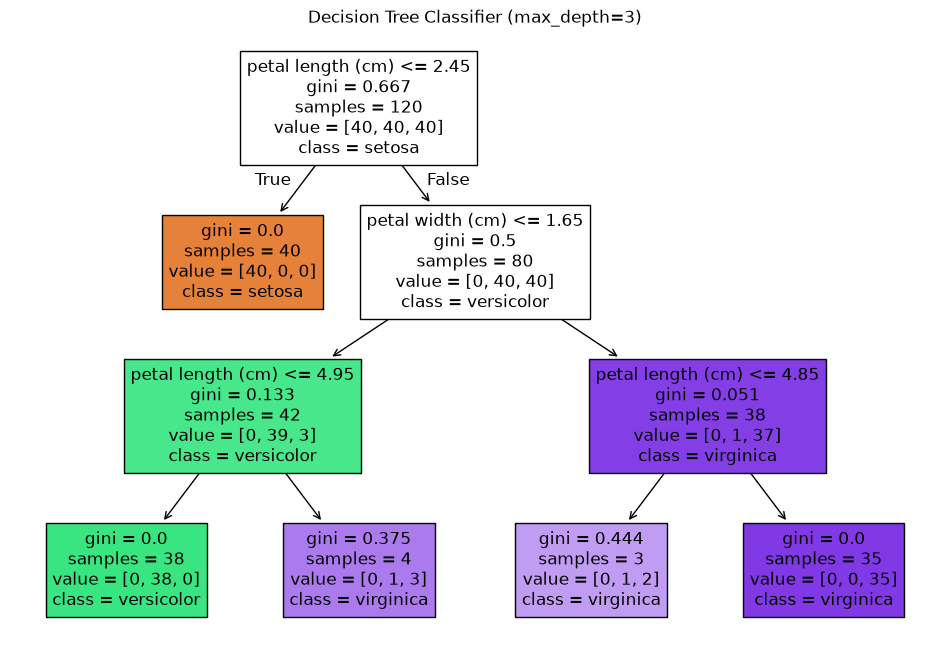

In [6]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

tree = DecisionTreeClassifier(
    max_depth=3, random_state=42
)
tree.fit(Xtr, ytr)
pred_tree = tree.predict(Xte)

print("First 10 Decision Tree predictions:", pred_tree[:10])

plt.figure(figsize=(12, 8))
plot_tree(
    tree,
    feature_names=Xc.columns,
    class_names=iris.target_names,
    filled=True
)
plt.title("Decision Tree Classifier (max_depth=3)")
plt.show()


In [7]:
from sklearn.svm import SVC

svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf")
)

svm.fit(Xtr, ytr)
pred_svm = svm.predict(Xte)
print("First 10 SVM predictions:", pred_svm[:10])


First 10 SVM predictions: [0 2 1 1 0 1 0 0 2 1]


In [8]:
from sklearn.metrics import accuracy_score

print("Classes:", iris.target_names)
print("Logistic accuracy:", accuracy_score(yte, pred_log))
print("Tree accuracy:", accuracy_score(yte, pred_tree))


Classes: ['setosa' 'versicolor' 'virginica']
Logistic accuracy: 0.9333333333333333
Tree accuracy: 0.9666666666666667


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

weighted = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=2000
    )
)

weighted.fit(Xtr, ytr)
pred_weighted = weighted.predict(Xte)

print("Balanced class weights enabled")
print("Weighted Logistic accuracy:", accuracy_score(yte, pred_weighted))


Balanced class weights enabled
Weighted Logistic accuracy: 0.9333333333333333


In [10]:
import pandas as pd
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(
    X_train_encoded, y_train
)

print("Before:\n", y_train.value_counts())
print("\nAfter:\n", pd.Series(y_res).value_counts())


NameError: name 'X_train_encoded' is not defined

In [11]:
import pandas as pd
from imblearn.over_sampling import SMOTE

# Create an imbalanced subset from Xtr, ytr (keep all of classes 0 & 1, only 10 of class 2)
idx_imbalanced = ytr[ytr != 2].index.union(ytr[ytr == 2].index[:10])
X_imb, y_imb = Xtr.loc[idx_imbalanced], ytr.loc[idx_imbalanced]

smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_imb, y_imb)

print("Before SMOTE:\n", y_imb.value_counts())
print("\nAfter SMOTE:\n", pd.Series(y_res).value_counts())


Before SMOTE:
 target
0    40
1    40
2    10
Name: count, dtype: int64

After SMOTE:
 target
0    40
1    40
2    40
Name: count, dtype: int64


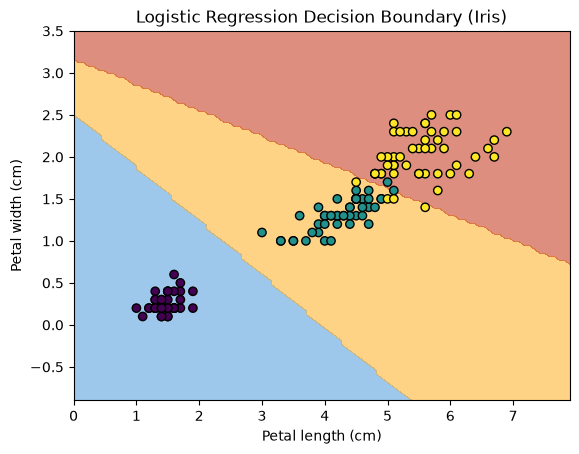

In [12]:
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

X2 = Xc[["petal length (cm)", "petal width (cm)"]]

boundary_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)
boundary_model.fit(X2, yc)

DecisionBoundaryDisplay.from_estimator(
    boundary_model,
    X2,
    response_method="predict",
    plot_method="contourf",
    alpha=0.5
)

plt.scatter(X2.iloc[:, 0], X2.iloc[:, 1], c=yc, edgecolor="k")
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Logistic Regression Decision Boundary (Iris)")
plt.show()


In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Accuracy:", accuracy_score(yte, pred_log))
print("Precision:", precision_score(yte, pred_log, average="weighted"))
print("Recall:", recall_score(yte, pred_log, average="weighted"))
print("F1:", f1_score(yte, pred_log, average="weighted"))


Accuracy: 0.9333333333333333
Precision: 0.9333333333333333
Recall: 0.9333333333333333
F1: 0.9333333333333333


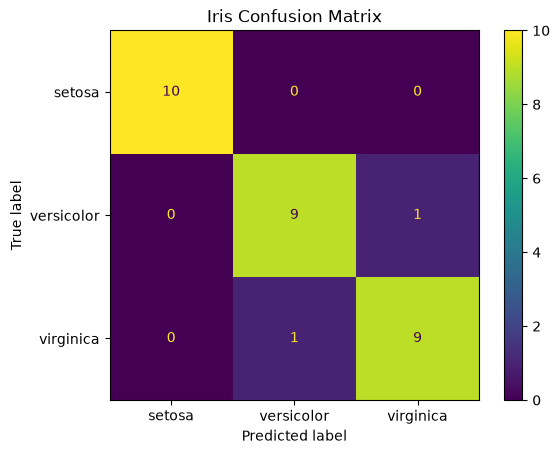

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    yte,
    pred_log,
    display_labels=iris.target_names
)
plt.title("Iris Confusion Matrix")
plt.show()


In [15]:
from sklearn.metrics import accuracy_score, f1_score

models = {
    "Logistic": log_model,
    "KNN": knn,
    "Naive Bayes": nb,
    "Decision Tree": tree,
    "SVM": svm
}

for name, model in models.items():
    pred = model.predict(Xte)
    print(
        name,
        "Accuracy:", round(accuracy_score(yte, pred), 3),
        "F1:", round(f1_score(yte, pred, average="weighted"), 3)
    )


Logistic Accuracy: 0.933 F1: 0.933
KNN Accuracy: 0.933 F1: 0.933
Naive Bayes Accuracy: 0.967 F1: 0.967
Decision Tree Accuracy: 0.967 F1: 0.967
SVM Accuracy: 0.967 F1: 0.967


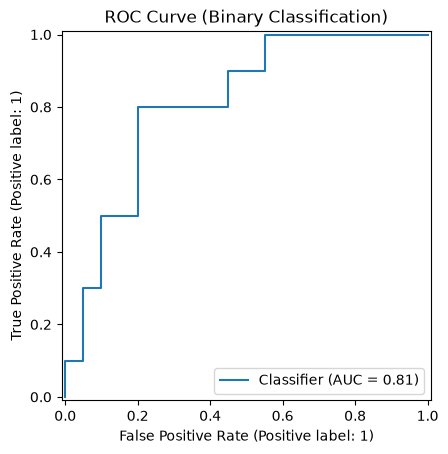

ROC-AUC: 0.81


In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Convert 3-class Iris target into binary (1 = class 1, 0 = otherwise)
ytr_binary = (ytr == 1).astype(int)
yte_binary = (yte == 1).astype(int)

# Fit a binary classifier that supports predict_proba
binary_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)
binary_model.fit(Xtr, ytr_binary)

# Predict probabilities for positive class (1) and plot ROC curve
probabilities = binary_model.predict_proba(Xte)[:, 1]

RocCurveDisplay.from_predictions(
    yte_binary,
    probabilities
)
plt.title("ROC Curve (Binary Classification)")
plt.show()

print("ROC-AUC:", round(roc_auc_score(yte_binary, probabilities), 4))
